# Cell-week dataset

Descriptive counts from the frozen local VIIRS S-NPP detection bundle and panel. The target is satellite detections, not fires, ignitions or burned area. No model is fitted or evaluated here. All calculations and plotting live in `bolivia_fire.figures`; rebuilding uses no network requests.

In [1]:
from bolivia_fire.figures import (
    build_dataset_artifacts,
    partition_summary_table,
    show_dataset_figure,
)

summary = build_dataset_artifacts()
print(f"Eligible cells: {summary['eligible_cells']:,}")
print(f"National cell area: {summary['national_area_km2']:,.1f} km?")
print(f"Issue weeks: {summary['issue_weeks']:,}")
print(f"Geographic holdout: {summary['held_out_blocks']} / {summary['eligible_blocks']} blocks")

Eligible cells: 37,146
National cell area: 1,068,783.8 km?
Issue weeks: 678
Geographic holdout: 24 / 124 blocks


The table gives descriptive label prevalence before fitting filters, separately for cells inside and outside the geographic holdout. A missing target label is excluded from the positive-rate denominator. The JSON also records annual detection counts, unobserved days and their documented causes, sequential fitting exclusions, and input hashes. Test-year prevalence is descriptive and supplies no model-selection evidence.

In [2]:
partition_summary_table(summary)

,partition,population,rows,labelled_rows,positive_rows,labelled_share,positive_rate
0,train,non_held_out,12274496,12215484,266764,0.9952,0.0218
1,train,held_out,3178240,3162960,48319,0.9952,0.0153
2,val_select,non_held_out,1504806,1475300,35086,0.9804,0.0238
3,val_select,held_out,389640,382000,6221,0.9804,0.0163
4,val_calib,non_held_out,1504806,1386782,42124,0.9216,0.0304
5,val_calib,held_out,389640,359080,8238,0.9216,0.0229
6,test,non_held_out,4632442,4189852,102917,0.9045,0.0246
7,test,held_out,1199480,1084880,18598,0.9045,0.0171


The map shows the share of complete, non-purged training weeks with at least one selected detection in each eligible cell. ADM0 and ADM1 outlines come from the pinned boundaries. Outlined 1? blocks are excluded from fitting, selection and calibration. National areas are geodesic intersections; the cells are not equal-area.

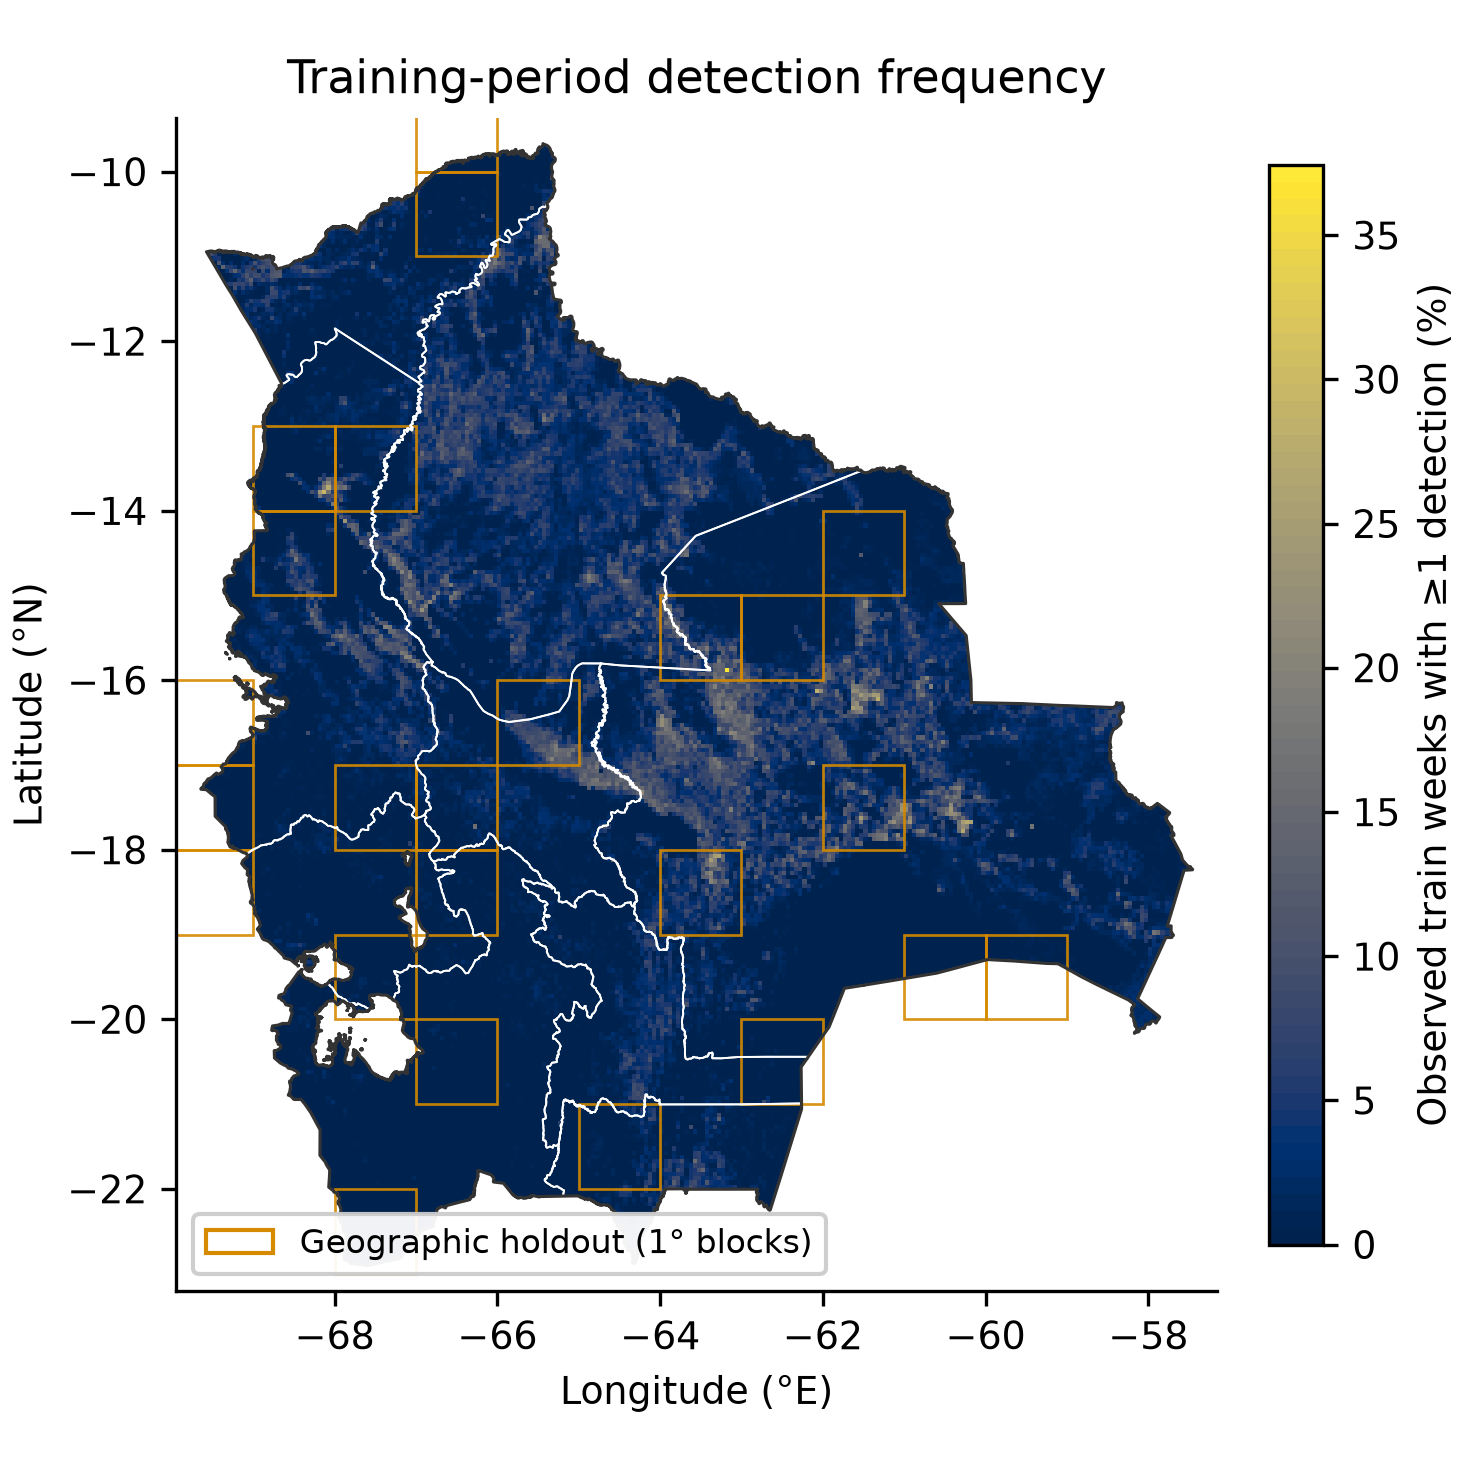

In [3]:
show_dataset_figure("map")

Weekly national counts include all observations covered by ADM0, including border points. Blue uses type 0 with nominal or high confidence; gray includes low confidence as well. Shading marks documented outage intervals and any missing acquisition dates. Counts during an incomplete week are partial observations. The first acquisition week is partial, and the series includes dates through December 31, 2025.

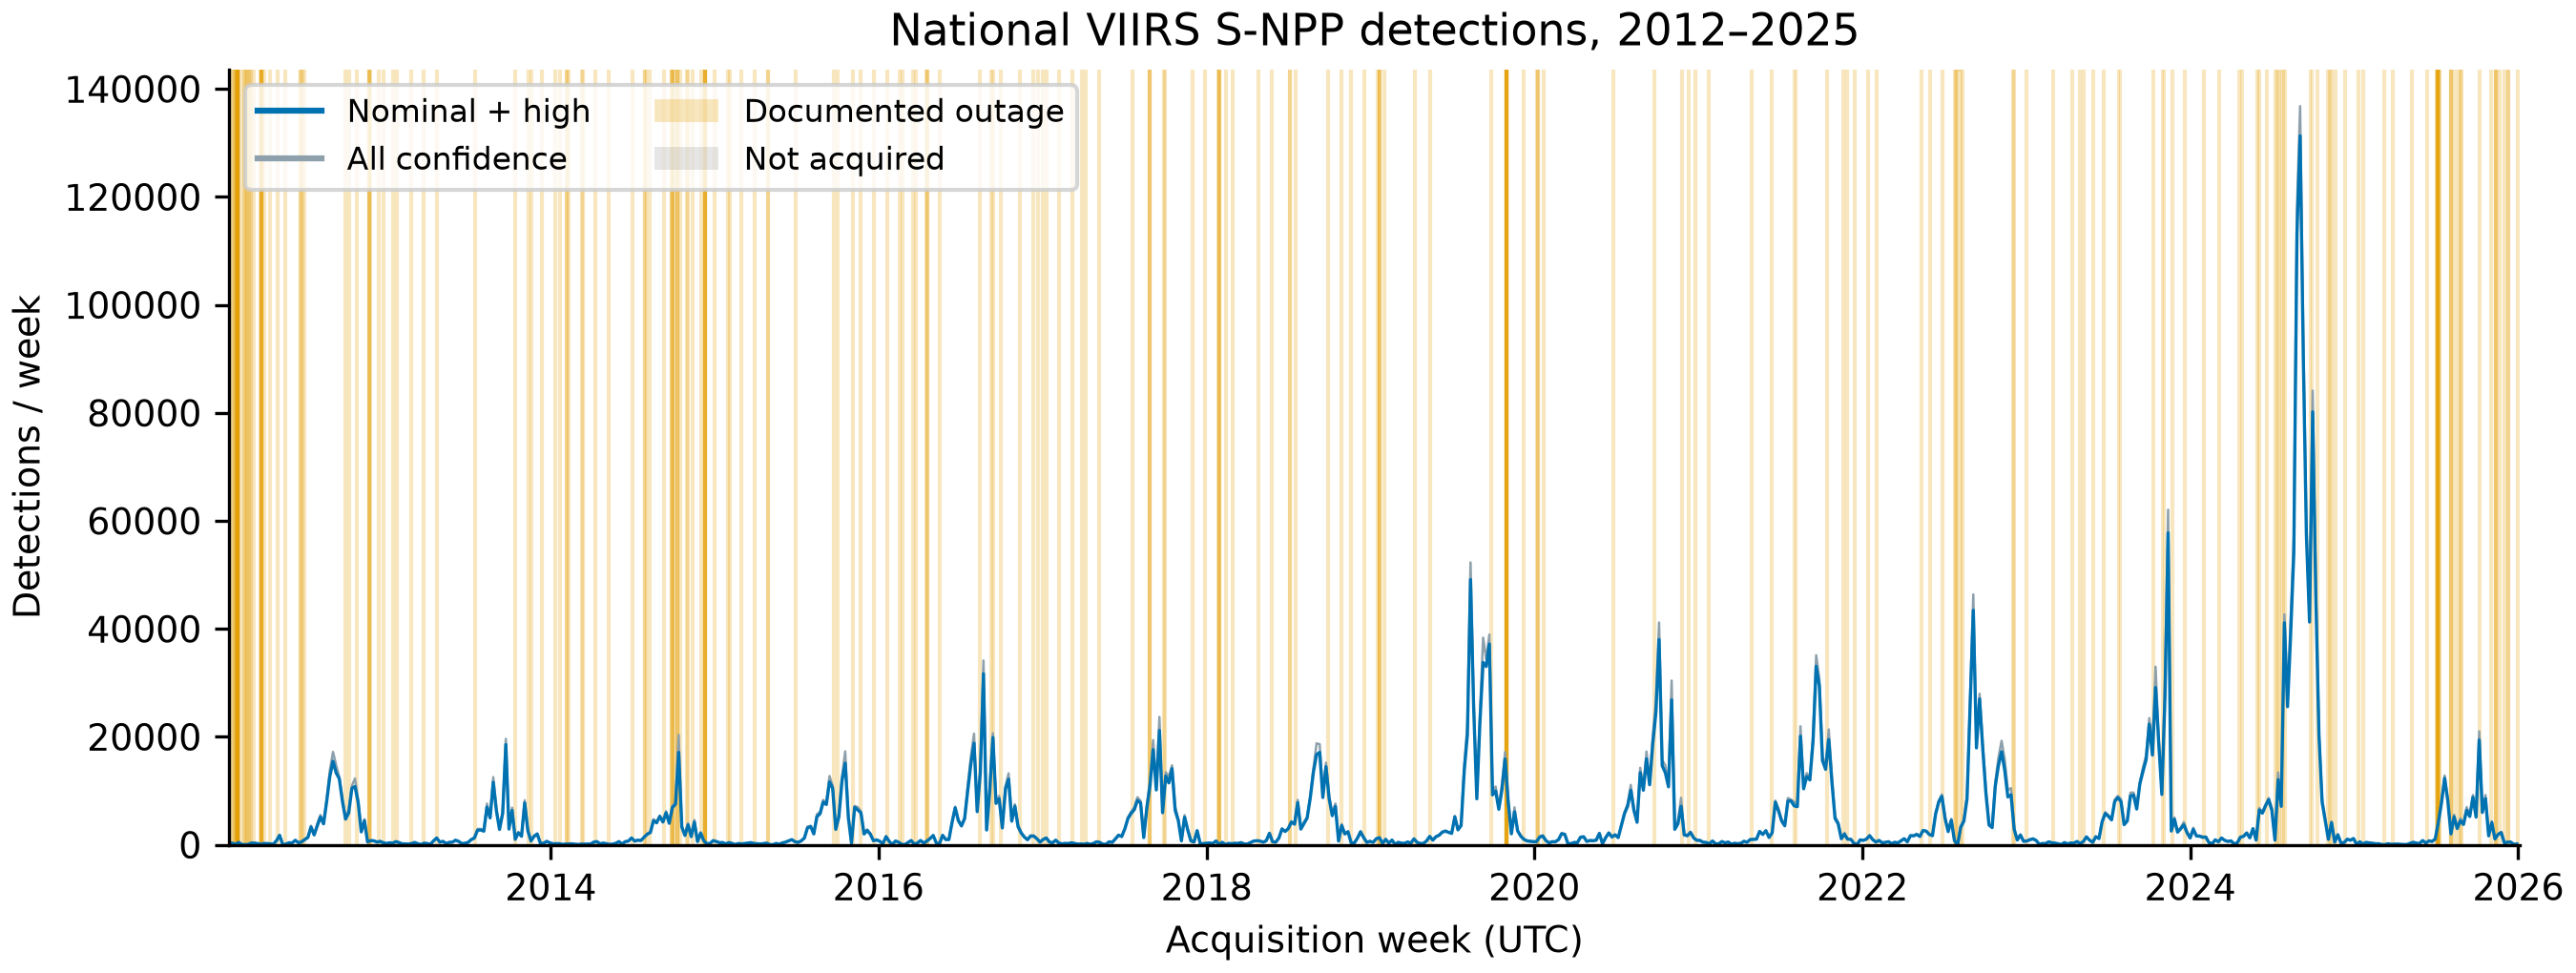

In [4]:
show_dataset_figure("weekly")

Each seasonal curve pools labelled cell-weeks across its partition years and both geographic populations. All labelled cell-weeks receive equal weight. The frozen calendar uses `min((day_of_year - 1) // 7, 51)`; gaps indicate absent labels or issue weeks, and the two final December Mondays can share index 51.

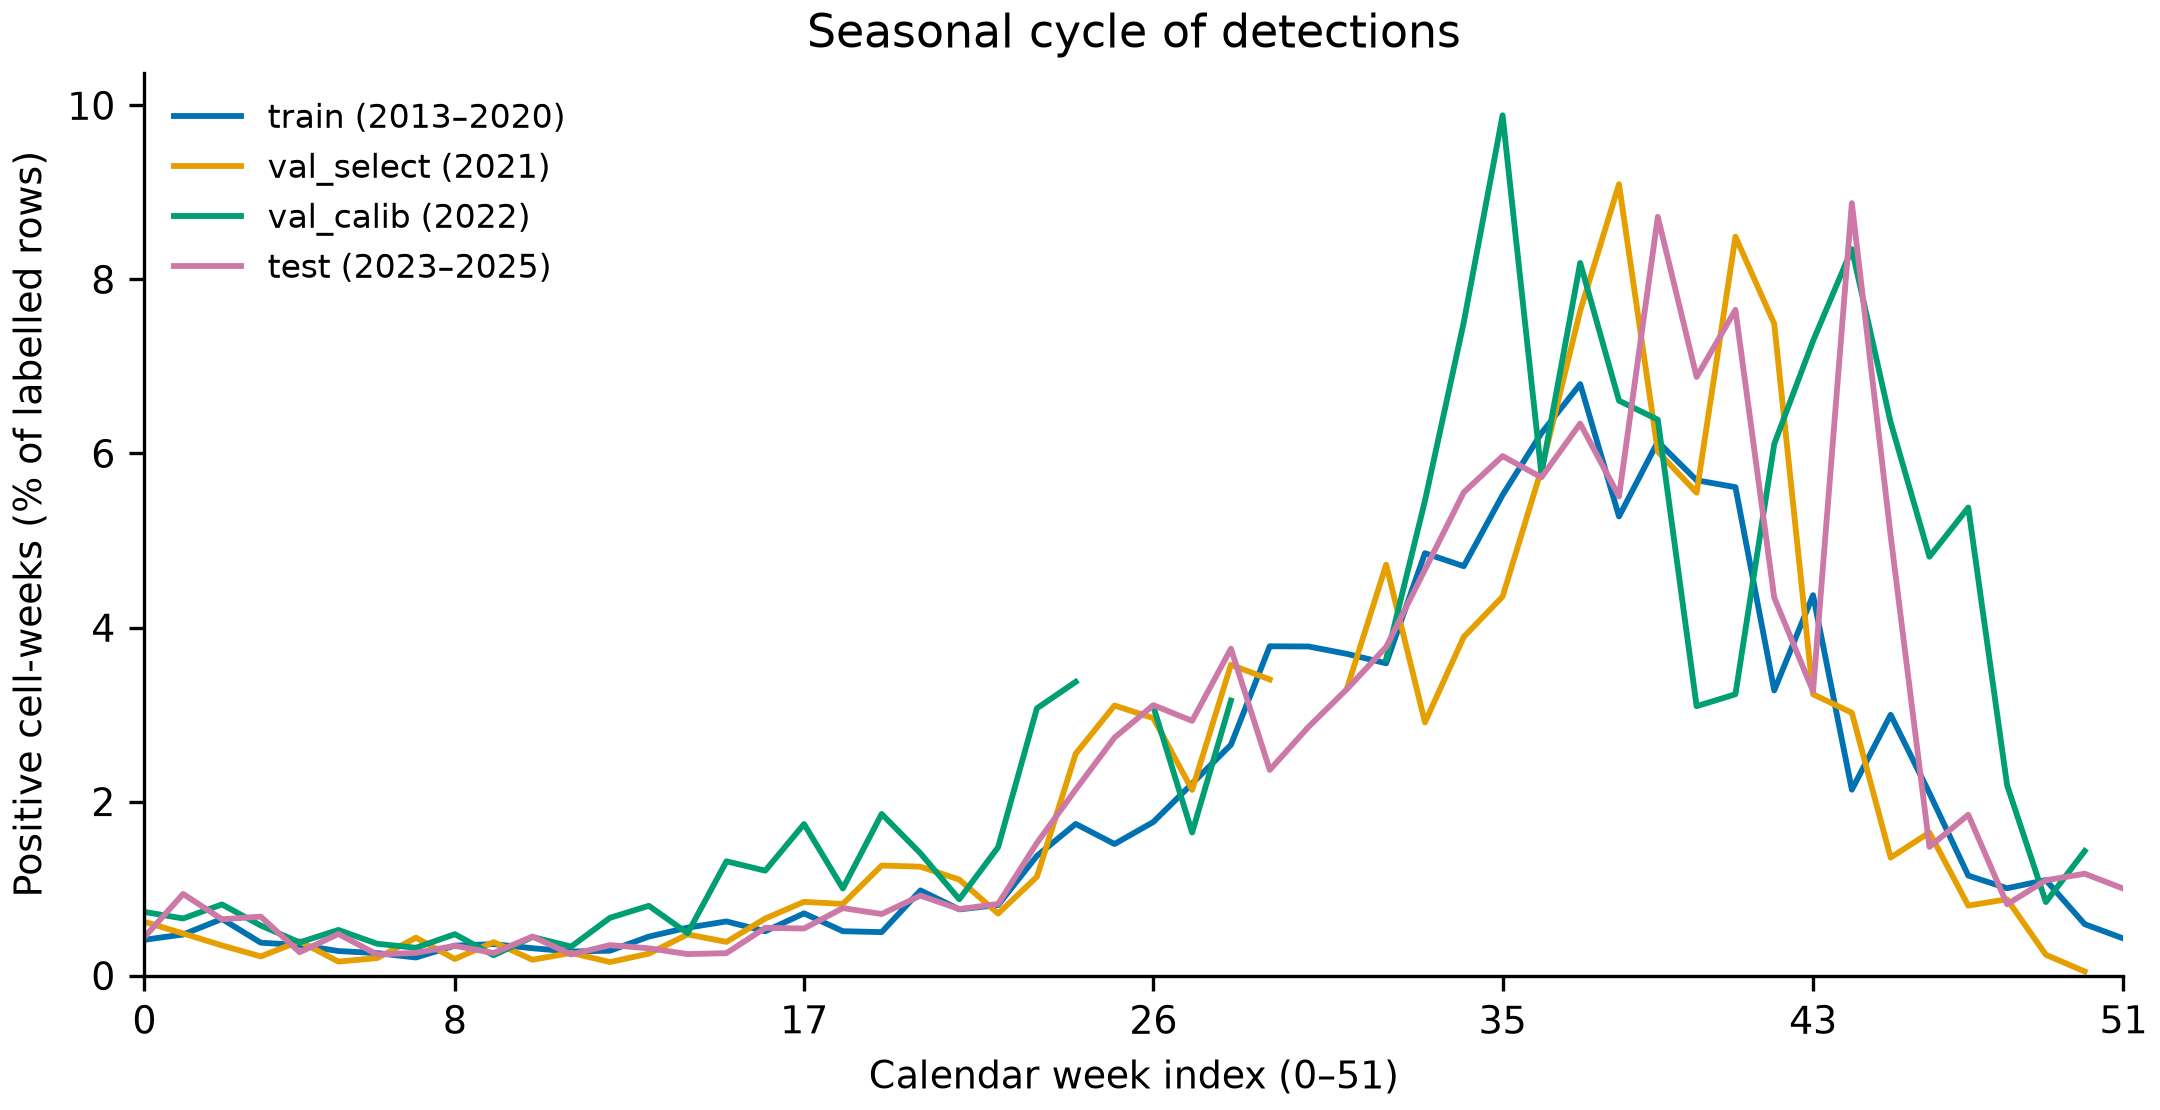

In [5]:
show_dataset_figure("seasonal")

The timeline retains Monday issue weeks and shades targets purged because their seven-day intervals cross a partition boundary. The final December 2025 issue remains in test, including its target days in January 2026. Held-out blocks remain excluded from all fitting, selection and calibration throughout the timeline. PNGs are written at 300 dpi in `artifacts/figures/`; PDFs are in the ignored `data/figures/` directory.

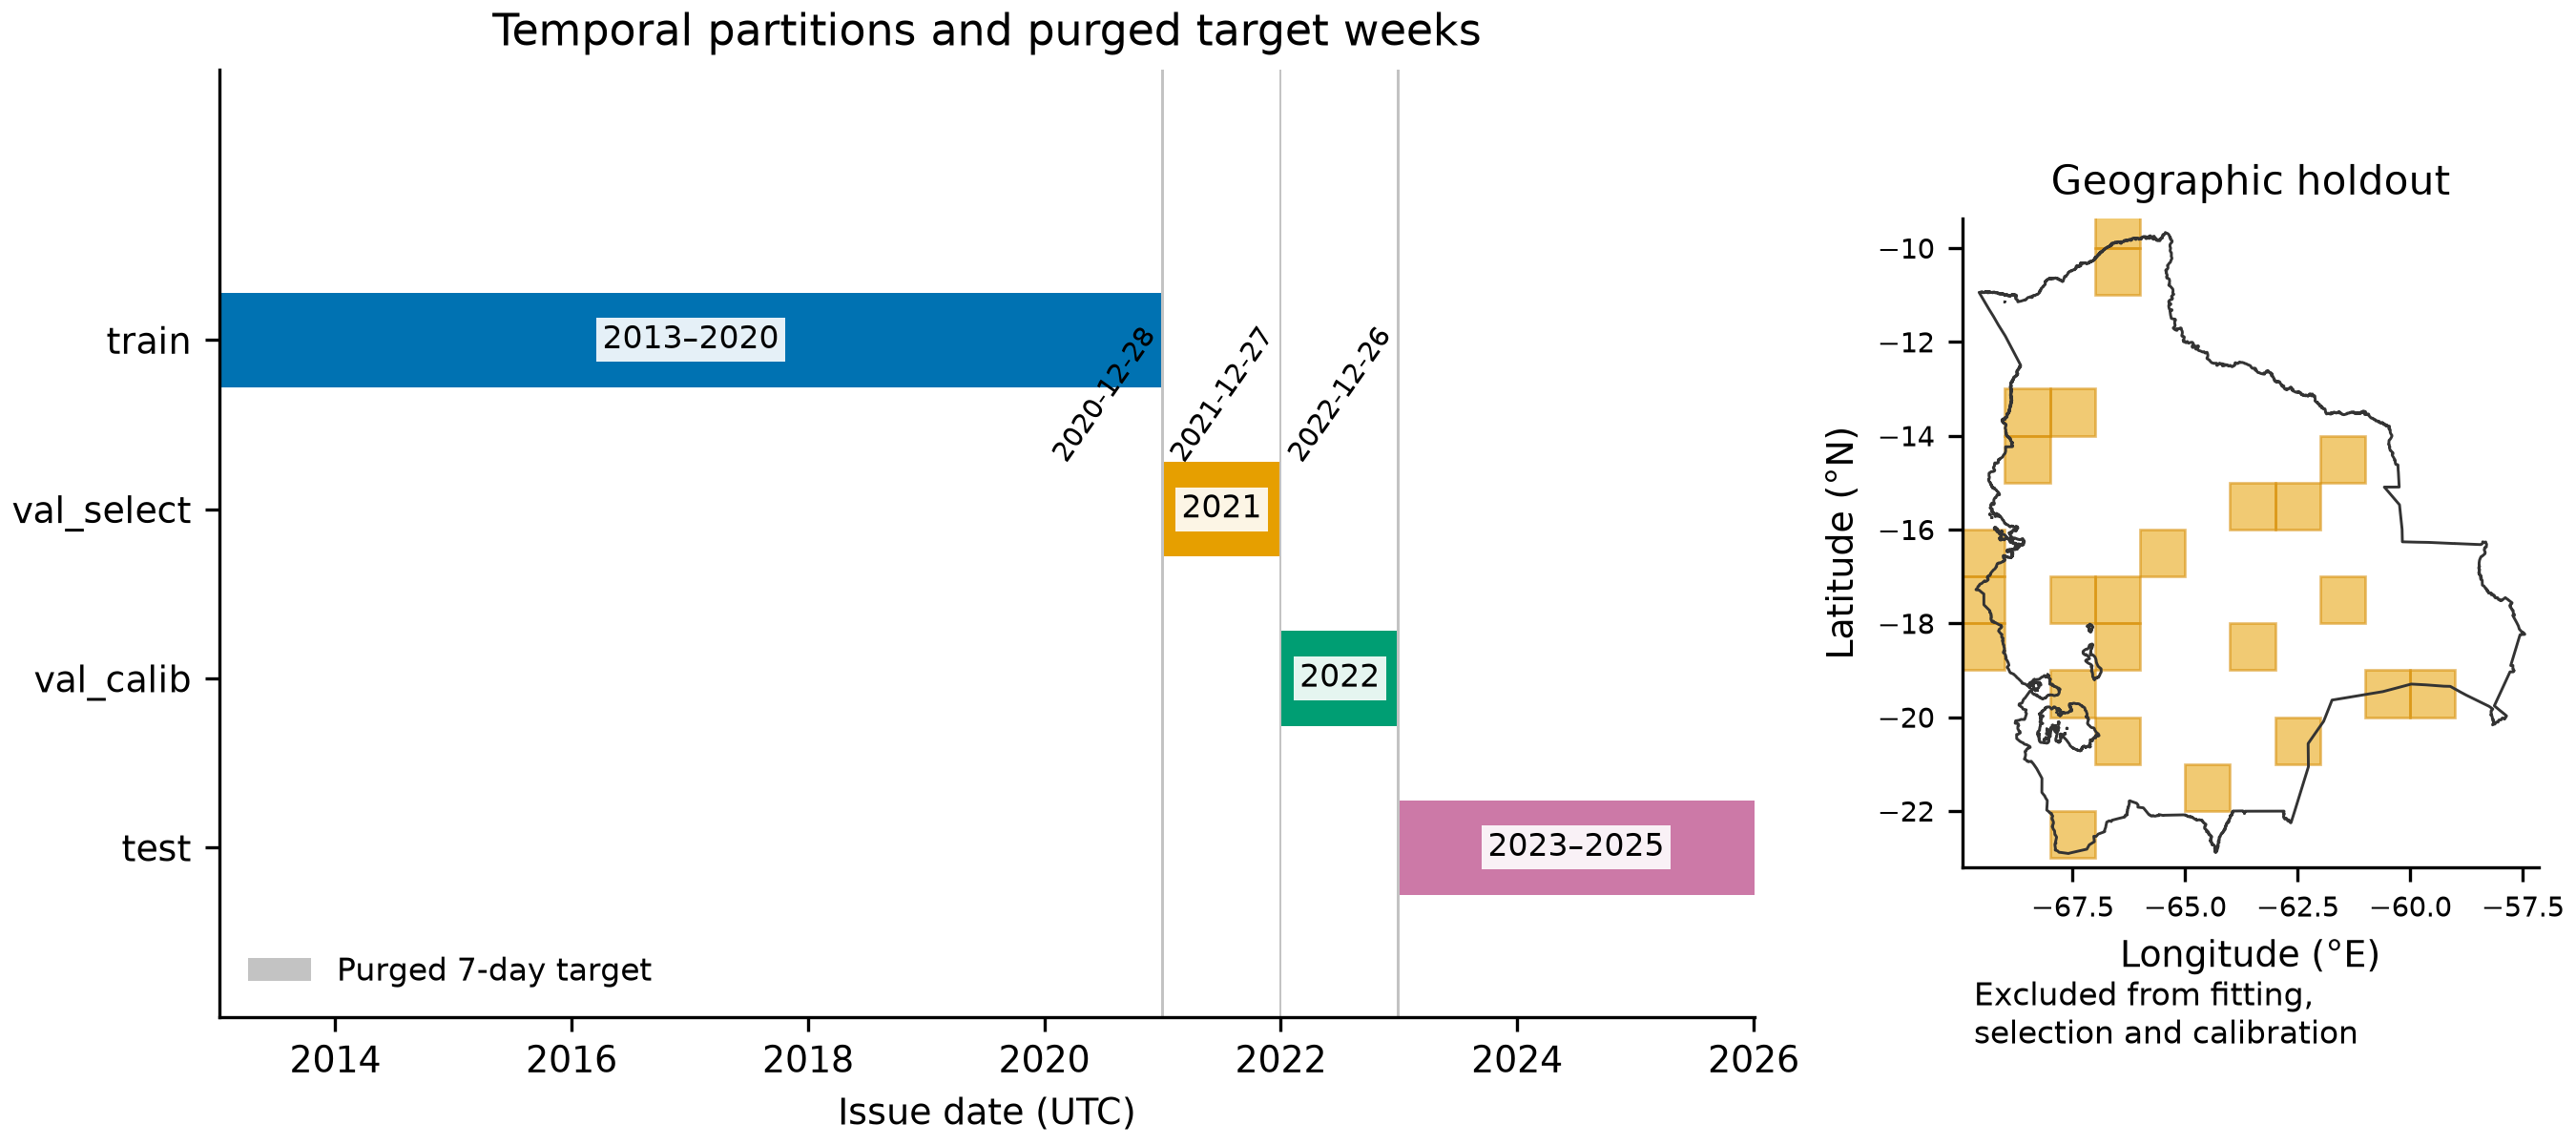

In [6]:
show_dataset_figure("partitions")